In [1]:
# Importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import joblib as jb   # pour sauvegarder les objets utilisés au déploiement

In [2]:
# Supprimer les warning
import warnings
warnings.filterwarnings("ignore")

### <font color = 'teal'>Importer et Lire les données<font>

In [6]:
# importer les données
df = pd.read_csv("Telephone_data.csv")
df.head()

,prix,adresse,marque,dim_ecr,ram,stockage,etat
0,580000,Guediawaye,iPhone,6.0,8,128,D'occasion
1,250000,Mermoz,iPhone,6.0,4,128,D'occasion
2,80000,Médina,iPhone,5.0,5,128,D'occasion
3,290000,Plateau,Samsung,6.0,8,256,D'occasion
4,250000,Mermoz,Samsung,6.0,8,256,D'occasion


In [7]:
# dimension des données
df.shape

(3253, 7)

In [8]:
# infos des données
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3253 entries, 0 to 3252
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   prix      3253 non-null   int64  
 1   adresse   3253 non-null   str    
 2   marque    3253 non-null   str    
 3   dim_ecr   3253 non-null   float64
 4   ram       3253 non-null   int64  
 5   stockage  3253 non-null   int64  
 6   etat      3253 non-null   str    
dtypes: float64(1), int64(3), str(3)
memory usage: 178.0 KB


### <font color = 'teal'>Exploration et preparation des données<font>



###### <font color = 'bisque'> Selection des variables catégorielles et quantitatives

In [9]:
# selection les variables catégorielles
categoriel_data = df.select_dtypes(exclude = 'number')
categoriel_data

,adresse,marque,etat
0,Guediawaye,iPhone,D'occasion
1,Mermoz,iPhone,D'occasion
2,Médina,iPhone,D'occasion
3,Plateau,Samsung,D'occasion
4,Mermoz,Samsung,D'occasion
...,...,...,...
3248,Médina,iPhone,Venant
3249,Pikine,Oppo,Venant
3250,Plateau,Xiaomi,Venant
3251,Dalifort,iPhone,Venant


In [10]:
# selection des variables quantitatives
number_data = df.select_dtypes(include = 'number')
number_data

,prix,dim_ecr,ram,stockage
0,580000,6.0,8,128
1,250000,6.0,4,128
2,80000,5.0,5,128
3,290000,6.0,8,256
4,250000,6.0,8,256
...,...,...,...,...
3248,410000,6.0,12,128
3249,140000,6.0,88,128
3250,375000,6.0,16,512
3251,365000,6.0,6,128


###### <font color = 'bisque'> Exploration des variables catégorielles

In [11]:
# décrire les variables catégorielles
categoriel_data.describe()

,adresse,marque,etat
count,3253,3253,3253
unique,43,28,4
top,Plateau,iPhone,Réconditionné
freq,415,1571,1053


In [12]:
# fonction de countplot
import plotly.express as px
def countplot_func(col):
    val = df[col].value_counts()
    fig = px.bar(x = val.index, y = val.values, color= val.index.astype(str), text_auto = True)
    fig.show()

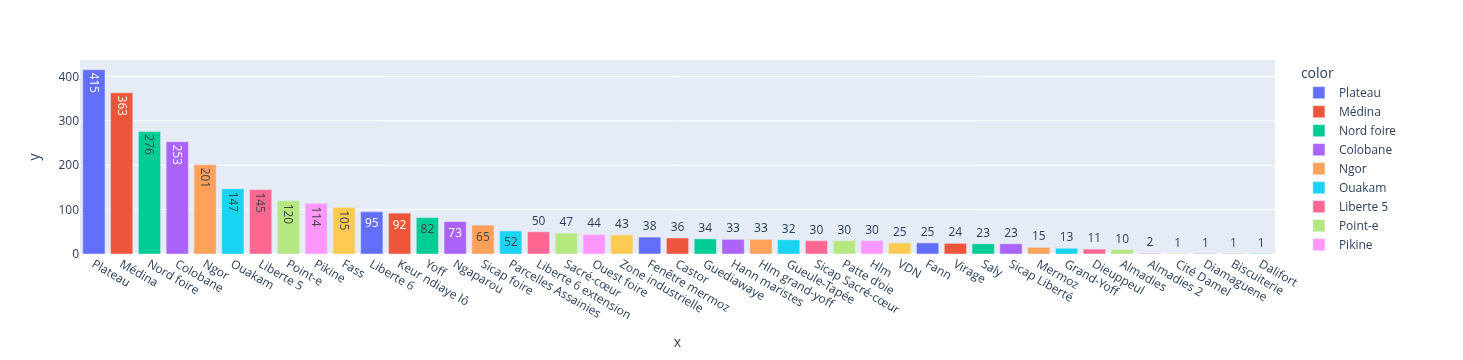

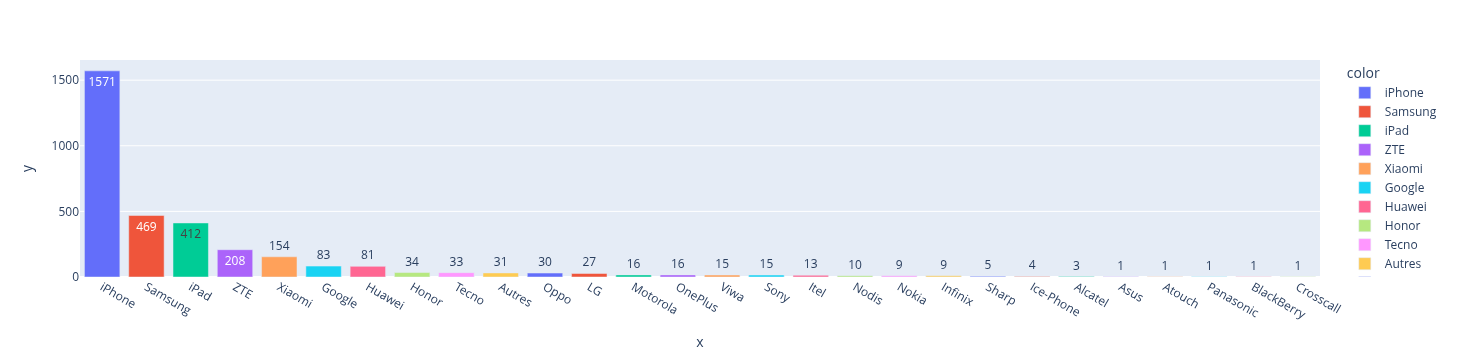

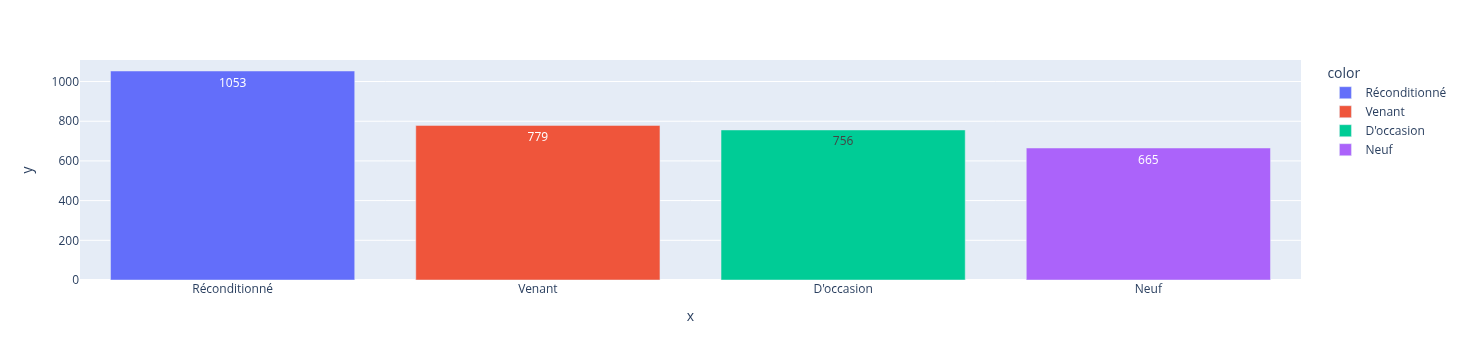

In [13]:
for col in categoriel_data:
    countplot_func(col)

###### <font color = 'bisque'> Exploration des variables quantitatives

In [14]:
# décrire les variables quantitatives
number_data.describe()

,prix,dim_ecr,ram,stockage
count,3.253000e+03,3253.000000,3253.000000,3253.000000
mean,3.608303e+05,6.510913,16.377498,193.514294
std,2.158010e+05,3.466092,20.291301,169.625904
min,1.000000e+00,0.000000,1.000000,1.000000
25%,2.370430e+05,6.000000,11.000000,128.000000
50%,3.620430e+05,6.000000,12.000000,158.000000
75%,4.620440e+05,7.000000,14.000000,256.000000
max,3.335000e+06,75.000000,512.000000,5120.000000


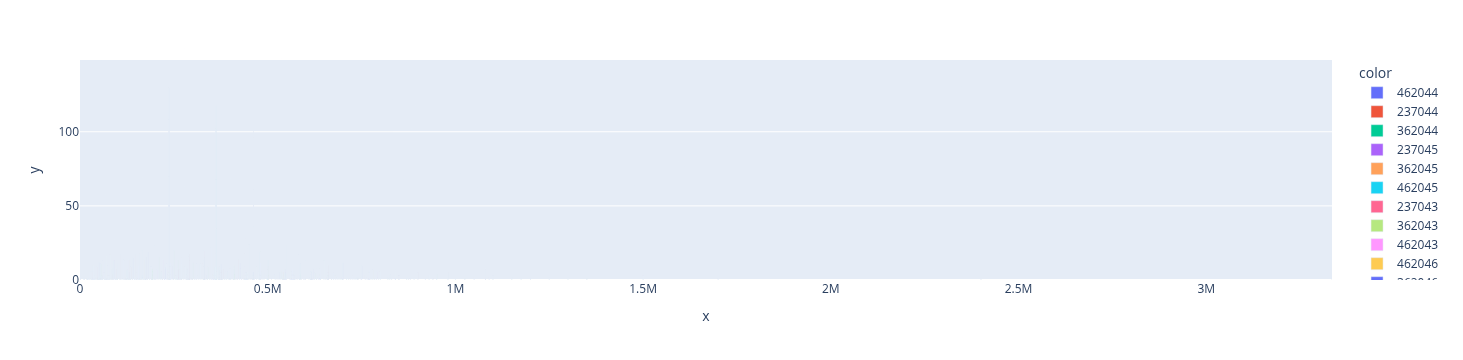

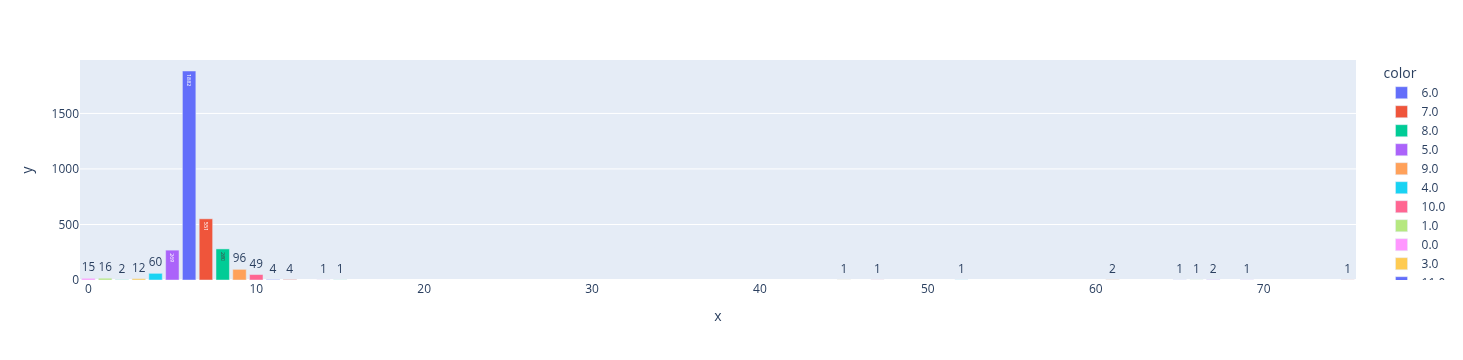

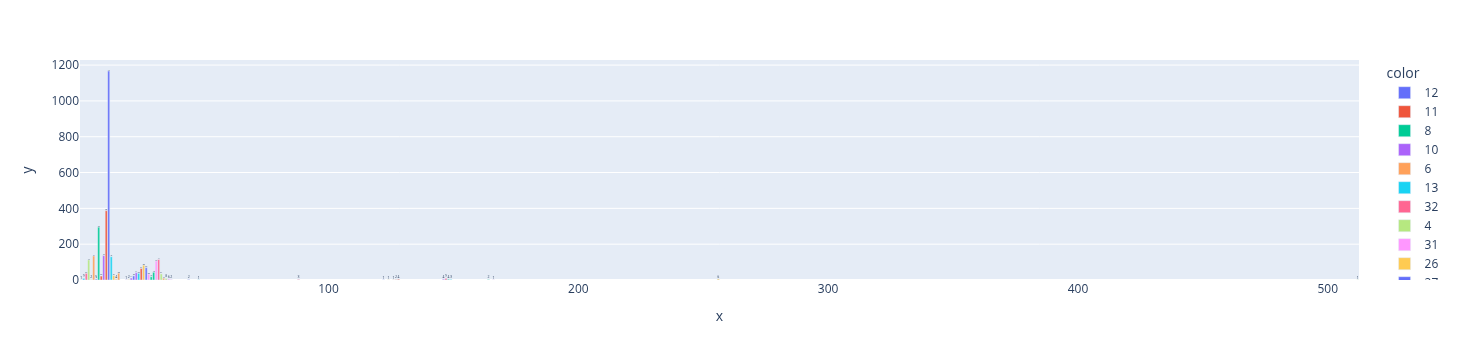

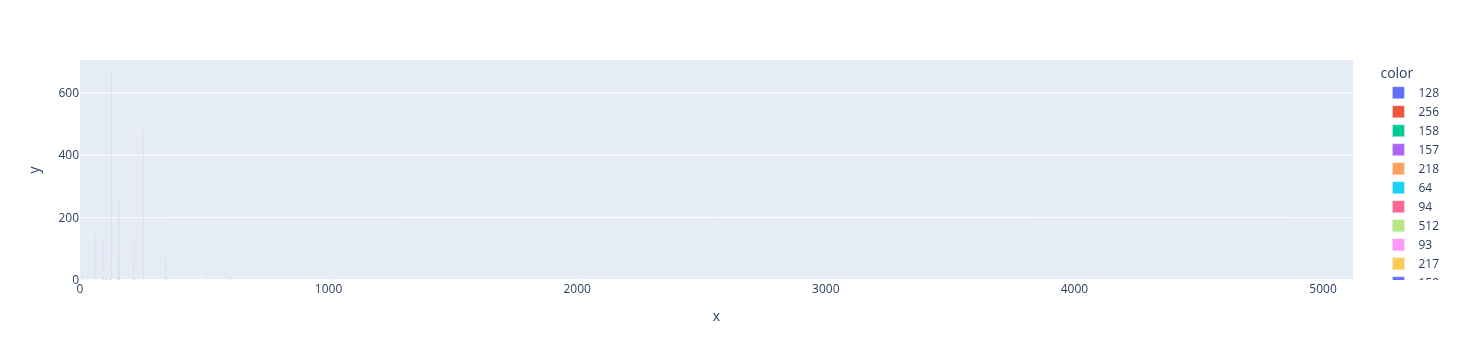

In [15]:
# pairplot des variables quantitatives
for col in number_data:
    countplot_func(col)

In [16]:
# fonction de visualisation des boxplots
def boxplot_func(col):
  plt.figure(figsize=(25,3))
  sns.boxplot(x=df[col])
  plt.show()

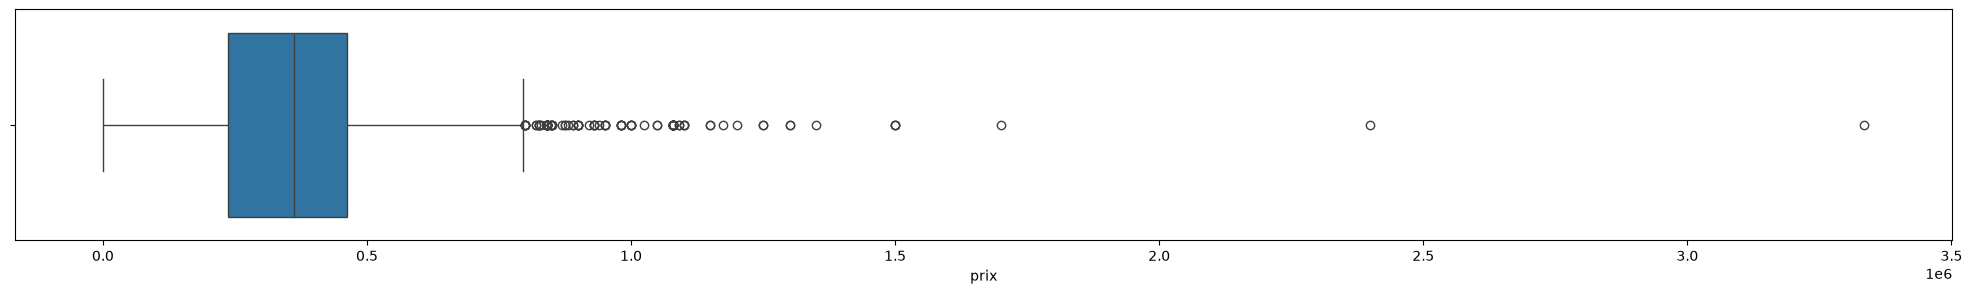

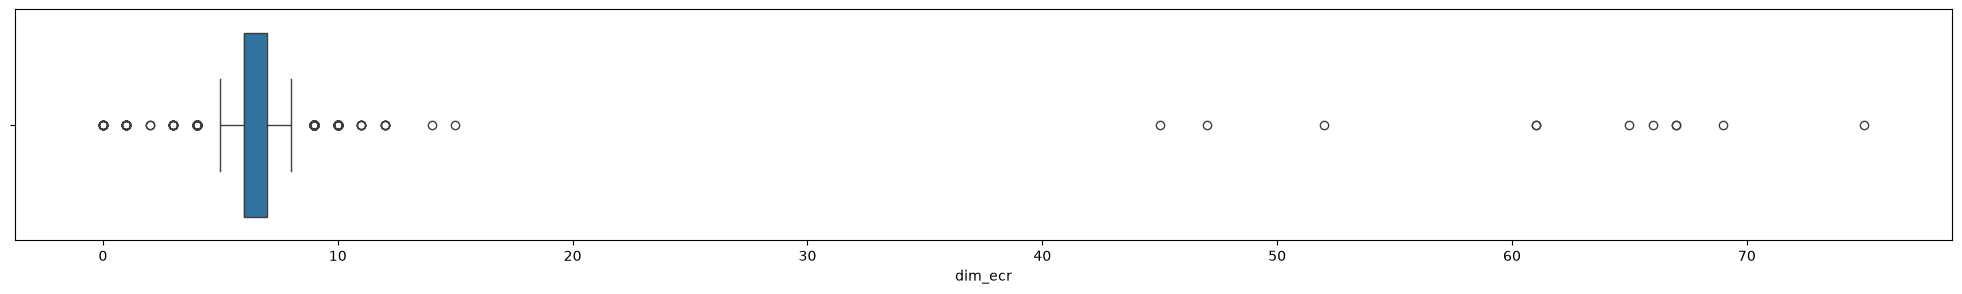

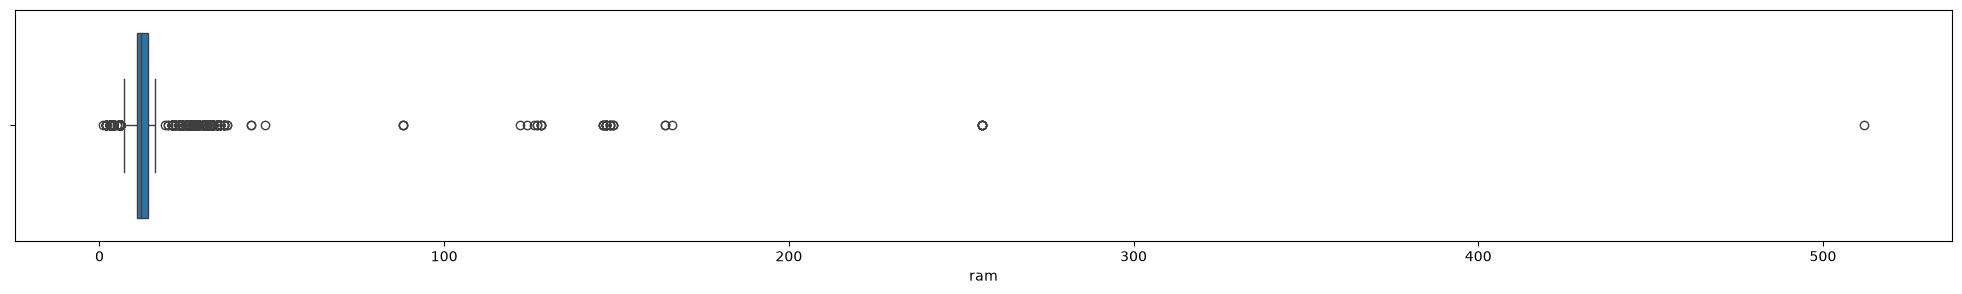

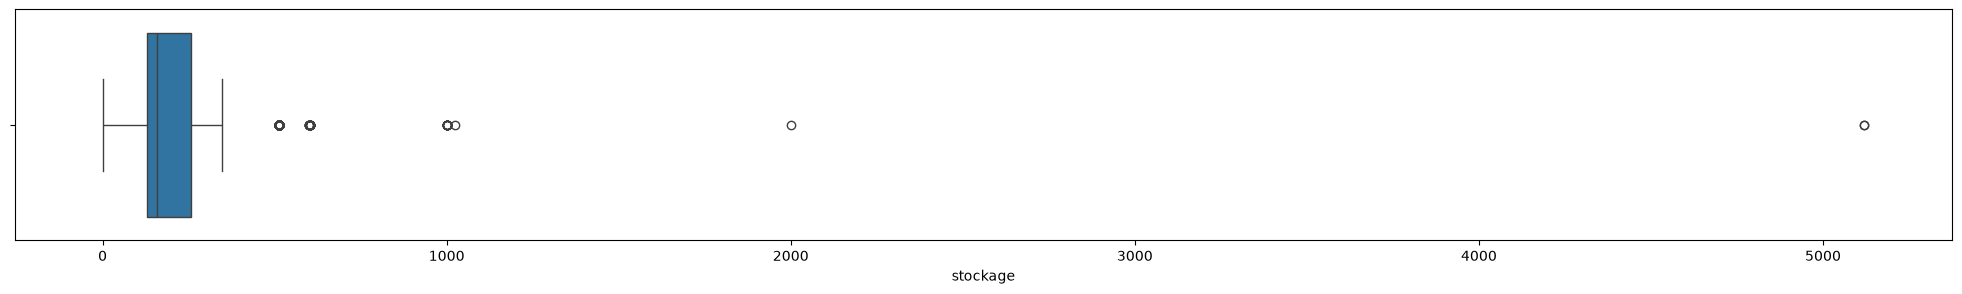

In [17]:
# boxplots des variables quantitatives
for col in number_data:
    boxplot_func(col)

###### <font color = 'bisque'> Preparation des données

In [19]:
# Enregistrer les valeurs uniques des variables catégorielles explicatives (listes déroulantes du déploiement)
uniques = {col: np.unique(df[col]).tolist() for col in categoriel_data.columns if col != 'etat'}
# sauvegarde
jb.dump(uniques, "telephone_uniques.joblib")
uniques['marque']

['Alcatel',
 'Asus',
 'Atouch',
 'Autres',
 'BlackBerry',
 'Crosscall',
 'Google',
 'Honor',
 'Huawei',
 'Ice-Phone',
 'Infinix',
 'Itel',
 'LG',
 'Motorola',
 'Nodis',
 'Nokia',
 'OnePlus',
 'Oppo',
 'Panasonic',
 'Samsung',
 'Sharp',
 'Sony',
 'Tecno',
 'Viwa',
 'Xiaomi',
 'ZTE',
 'iPad',
 'iPhone']

In [21]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder

# un encodeur par variable catégorielle 
encoders = {}
for col in categoriel_data.columns:
    encoder = LabelEncoder()
    df[col] = encoder.fit_transform(df[col])
    encoders[col] = encoder

# classes de la variable cible, dans l'ordre de leurs codes 0, 1, 2, 3
classnames = encoders['etat'].classes_
classnames

array([0, 1, 2, 3])

In [22]:
# sauvegarde des encodeurs
jb.dump(encoders, "encoders_classif_telephone.joblib")

['encoders_classif_telephone.joblib']

In [23]:
from sklearn.impute import KNNImputer
# fonction d'imputation des valeurs aberrantes
# (définie mais NON appliquée ici, comme dans la version d'origine : l'IQR considère comme aberrantes
#  des valeurs légitimes, par ex. ram = 4 ou 6, stockage = 512)
def impute_func(df, col, n_neighbors=5):
    # 2. Détection des outliers (Méthode IQR)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    min_value = Q1 - 1.5 * IQR
    max_value = Q3 + 1.5 * IQR

    # Les valeurs hors bornes deviennent des valeurs manquantes pour le KNNImputer
    df.loc[(df[col] < min_value) | (df[col] > max_value), col] = np.nan
    # n_neighbors : nombre de voisins pour calculer la moyenne de remplacement
    imputer = KNNImputer(n_neighbors=n_neighbors)
    df[:] = imputer.fit_transform(df)

In [24]:
# Application du traitement valeurs aberantes
for col in number_data :
    impute_func(df,col)

In [26]:
# Fractionner les données en variables prédicteurs (x) et variable cible (y)
x = df.drop('etat', axis = 1).values
y = df.etat.values

# ordre des variables explicatives (à respecter lors des prédictions)
features = df.drop('etat', axis = 1).columns.tolist()
jb.dump(features, "telephone_features.joblib")
features

['prix', 'adresse', 'marque', 'dim_ecr', 'ram', 'stockage']

In [27]:
#données d'entrainement

from sklearn.model_selection import train_test_split
x_train, x_val_test, y_train, y_val_test = train_test_split(x, y, train_size = 0.8, random_state = 42)
x_val, x_test, y_val, y_test = train_test_split(x_val_test, y_val_test, train_size = 0.5, random_state = 42)

In [30]:
# normaliser les données : le scaler est ajusté sur le train uniquement, puis appliqué à val et test
from sklearn.preprocessing import MinMaxScaler # Z = (X -Xmin)/(Xmax -Xmin)
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)
x_test = scaler.transform(x_test)
x_train[:5]

array([[0.54087993, 0.54761905, 0.22222222, 0.33333333, 0.55555556,
        0.36599424],
       [0.45539931, 0.64285714, 0.96296296, 0.        , 0.44444444,
        0.44956772],
       [0.29816893, 0.61904762, 0.96296296, 0.33333333, 0.44444444,
        0.26512968],
       [0.58118815, 0.42857143, 0.92592593, 0.66666667, 0.44444444,
        0.44956772],
       [0.29816641, 0.61904762, 0.96296296, 0.66666667, 0.44444444,
        0.26801153]])

In [31]:
# sauvegarde du scaler
jb.dump(scaler, "scaler_classif_telephone.joblib")

['scaler_classif_telephone.joblib']

### <font color = 'teal'>Fonctions d'évaluation<font>

In [32]:
# fonction d'évaluation
from sklearn.metrics import f1_score, accuracy_score
def evaluation(model):
  y_pred = model.predict(x_val)
  acc = accuracy_score(y_val, y_pred)
  f1 = f1_score(y_val, y_pred, average='weighted')
  return acc, f1

In [33]:
# Importer ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# y_pred:  prédictions du modèle sur les données validation
def CM_visualisation(model_objet):

    y_pred = model_objet.predict(x_val)
    # Confusion matrix
    cnf_matr = confusion_matrix(y_val, y_pred, labels=np.arange(len(classnames)))

    # Utiliser ConfusionMatrixDisplay pour visualiser la matrice de confusion
    disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matr,
                                  display_labels=classnames)
    disp.plot() 
    plt.title('Matrice de confusion') 
    plt.show() 

### <font color = 'teal'>Logistic Regression<font>

###### <font color = 'bisque'> Recherche des paramètre optimaux

In [34]:
from sklearn.model_selection import GridSearchCV, KFold
# Recherche des paramètres optimaux pour la logistic regression
from sklearn.linear_model import LogisticRegression
cv = KFold(n_splits = 5, shuffle =True, random_state= 42)
# dictionnaire params
params_lg = {"C":np.logspace(-3,3,10),"penalty": ['l1','l2']}
# instantier le modèle Logistic regression 
lg = LogisticRegression(solver = 'saga', max_iter = 2000)

grid_lg = GridSearchCV(lg, params_lg, cv = cv, n_jobs = -1)

grid_lg.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...solver='saga')
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': array([1.0000...00000000e+03]), 'penalty': ['l1', 'l2']}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Control

In [35]:
# Afficher les paramètres optimaux
grid_lg.best_params_

{'C': np.float64(0.46415888336127775), 'penalty': 'l1'}

###### <font color = 'bisque'> Entrainement du modèle

In [36]:
lg_model = grid_lg.best_estimator_

###### <font color = 'bisque'> Evaluation du modèle

In [37]:
# Accuracy et F1 score du modèle sur les données de validation
acc_lg ,f1_lg = evaluation(lg_model)
print(f"accuracy : {acc_lg} -------F1-Score : {f1_lg}")

accuracy : 0.6861538461538461 -------F1-Score : 0.669378266103785


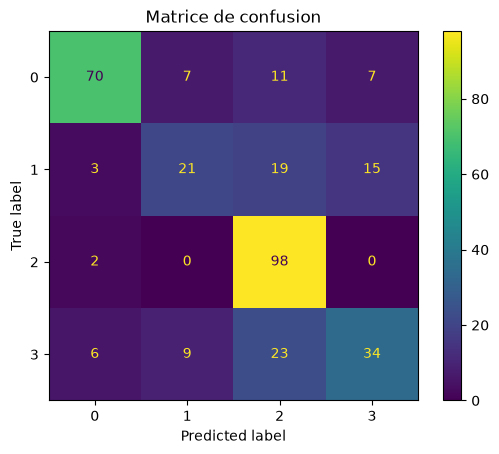

In [38]:
# Matrice de confusion
CM_visualisation(lg_model)

### <font color = 'teal'>Decision Tree<font>

###### <font color = 'bisque'> Recherche des paramètre optimaux

In [39]:
# Recherche des paramètres optimaux pour le Decision Tree
from sklearn.tree import DecisionTreeClassifier
cv = KFold(n_splits = 5, shuffle =True, random_state= 42)

# dictionnaire des params
params_dt = {'criterion':['gini','entropy'],'max_depth':np.arange(3,15)}
# instantier le modèle Decision Tree
dt = DecisionTreeClassifier(random_state = 42)
# instantier le modèle gridsearch
grid_dt = GridSearchCV(dt, params_dt, cv = cv, n_jobs = -1)
grid_dt.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': array([ 3, 4..., 12, 13, 14])}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, 

In [40]:
# afficher les paramètres optimaux
grid_dt.best_params_

{'criterion': 'gini', 'max_depth': np.int64(13)}

###### <font color = 'bisque'> Entrainement du modèle

In [41]:
# Récupérer le modèle optimal
tree_model = grid_dt.best_estimator_

###### <font color = 'bisque'> Evaluation du modèle

In [42]:
# Accuracy et F1 score du modèle sur les données de validation
acc_tree ,f1_tree = evaluation(tree_model)
print(f"accuracy : {acc_tree} -------F1-Score : {f1_tree}")

accuracy : 0.8215384615384616 -------F1-Score : 0.8223001020673594


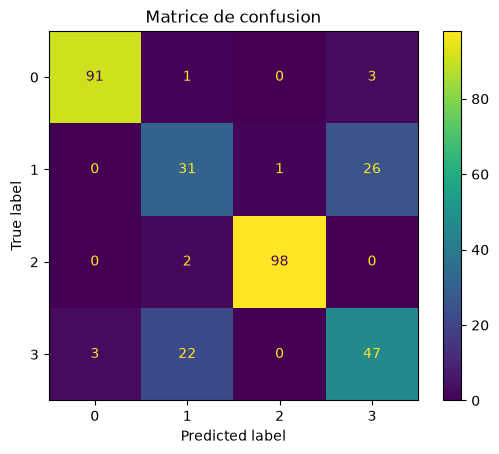

In [43]:
# Matrice de confusion
CM_visualisation(tree_model)

### <font color = 'teal'>Random Forest<font>

In [44]:
# Recherche des paramètres optimaux pour le Random Forest
from sklearn.ensemble import RandomForestClassifier
# dictionnaire des  params
params_rf = {
    'n_estimators': list(np.arange(10,100,10)),
    'max_depth' : list(np.arange(3,15)),
    'criterion' :['gini', 'entropy']
}
cv = KFold(n_splits = 5, shuffle =True, random_state= 42)

# instantier le modèle Random Forest
rf = RandomForestClassifier(random_state = 42)
# instantier le modèle gridsearch
grid_rf = GridSearchCV(estimator=rf, param_grid=params_rf, cv= cv, n_jobs = -1)
grid_rf.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [np.int64(3), np.int64(4), ...], 'n_estimators': [np.int64(10), np.int64(20), ...]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Suppo

In [45]:
# Afficher les paramètres optimaux
grid_rf.best_params_

{'criterion': 'gini', 'max_depth': np.int64(10), 'n_estimators': np.int64(90)}

In [46]:
# Récupérer le modèle optimal
rf_model = grid_rf.best_estimator_

##### <font color ='bisque'>Evaluation du Random Forest<font>

In [47]:
# Accuracy et F1 score du modèle sur les données de validation
acc_rf ,f1_rf = evaluation(rf_model)
print(f"accuracy : {acc_rf} -------F1-Score : {f1_rf}")

accuracy : 0.8707692307692307 -------F1-Score : 0.8715096758307004


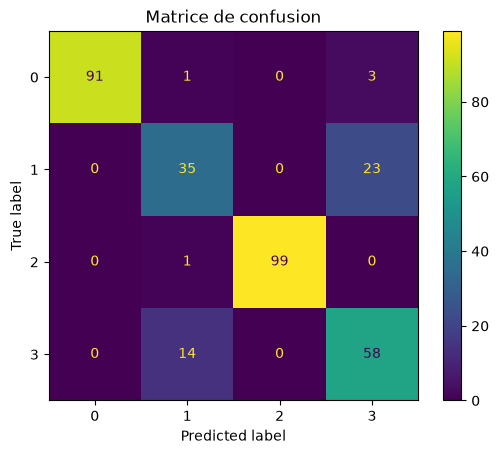

In [48]:
# Matrice de confusion
CM_visualisation(rf_model)

### <font color = 'teal'>Comparaison des modèles<font>

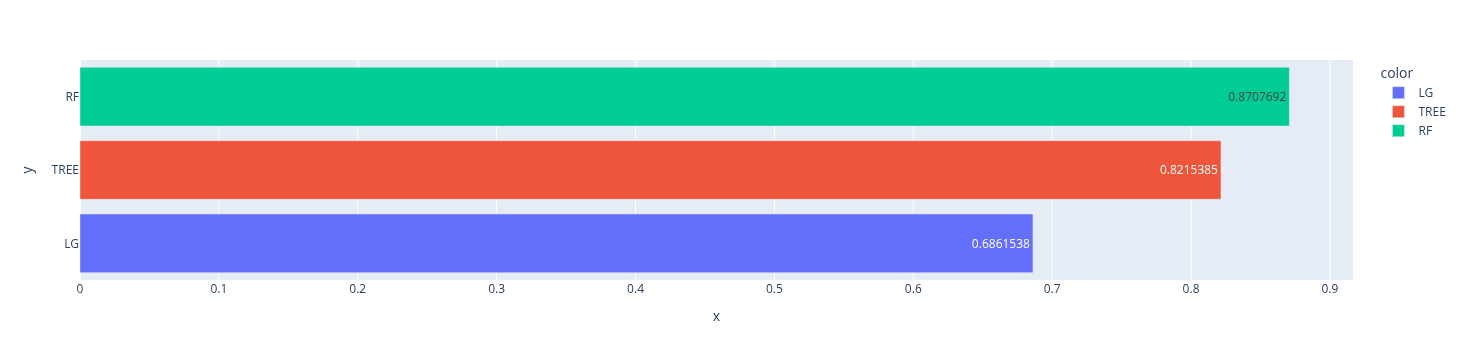

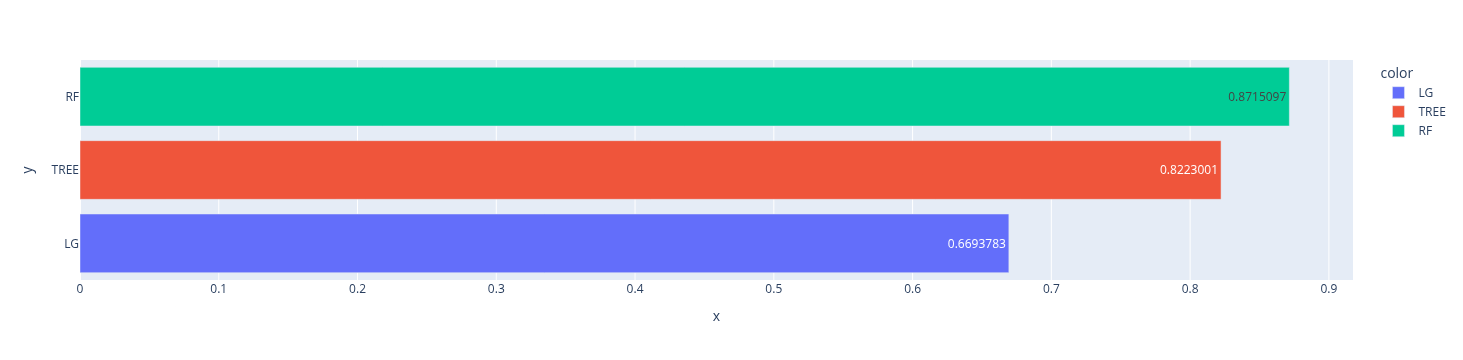

In [49]:
# diagramme de performances
list_names = ['LG', 'TREE','RF']
list_acc = [acc_lg, acc_tree, acc_rf]
list_f1 = [f1_lg,f1_tree, f1_rf]
list_final = [list_acc, list_f1]

for i in range(2):

    fig = px.bar(y = list_names, x = list_final[i], color = list_names, text_auto = True)
    fig.show()

### <font color = 'teal'>Sélection et sauvegarde du modèle le plus performant<font>

In [50]:
# le modèle retenu est celui qui a la meilleure accuracy sur les données de validation
models = {'LG': lg_model, 'TREE': tree_model, 'RF': rf_model}
best_name = list_names[int(np.argmax(list_acc))]
best_model = models[best_name]
print(f"Modèle le plus performant : {best_name} (accuracy validation = {max(list_acc):.4f})")

Modèle le plus performant : RF (accuracy validation = 0.8708)


In [51]:
# télécharger le modèle le plus performant
jb.dump(best_model, "model_classif_telephone.joblib")

['model_classif_telephone.joblib']

### <font color ='bisque'>Tester le modèle le plus performant<font>

In [54]:
# echantillons
x_test_10 = x_test[:10]
y_test_10 = y_test[:10]

# predictions
y_pred_10 = best_model.predict(x_test_10)
# retrouver les libellés d'origine à partir des codes
pred_names = encoders['etat'].inverse_transform(y_pred_10)
real_names = encoders['etat'].inverse_transform(y_test_10)

for i in range(10):
    print(f"Prédiction {i + 1} : {pred_names[i]} -- Réel : {real_names[i]}")

Prédiction 1 : 3 -- Réel : 3
Prédiction 2 : 1 -- Réel : 1
Prédiction 3 : 0 -- Réel : 0
Prédiction 4 : 0 -- Réel : 0
Prédiction 5 : 0 -- Réel : 0
Prédiction 6 : 2 -- Réel : 2
Prédiction 7 : 3 -- Réel : 3
Prédiction 8 : 1 -- Réel : 3
Prédiction 9 : 2 -- Réel : 2
Prédiction 10 : 3 -- Réel : 3
